In [39]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [40]:
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid

In [41]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

In [42]:
transform = transforms.ToTensor()

In [43]:
train_data = datasets.MNIST(
    root="./Data", train=True, download=True, transform=transform
)
test_data = datasets.MNIST(
    root="./Data", train=False, download=True, transform=transform
)

In [44]:
train_data

Dataset MNIST
    Number of datapoints: 60000
    Root location: ./Data
    Split: Train
    StandardTransform
Transform: ToTensor()

In [45]:
test_data

Dataset MNIST
    Number of datapoints: 10000
    Root location: ./Data
    Split: Test
    StandardTransform
Transform: ToTensor()

In [46]:
image, label = train_data[0]
image.shape

torch.Size([1, 28, 28])

In [47]:
label

5

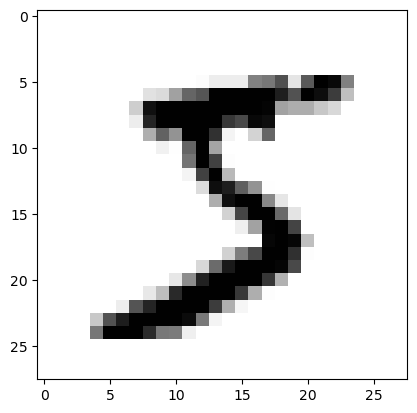

In [48]:
plt.imshow(image.reshape(28, 28), cmap="gist_yarg")
# viridis by default

In [49]:
torch.manual_seed(101)
train_loader = DataLoader(train_data, batch_size=100, shuffle=True)
test_loader = DataLoader(test_data, batch_size=500, shuffle=False)

In [50]:
type(train_loader)

torch.utils.data.dataloader.DataLoader

In [51]:
for images, labels in train_loader:
    break

print(images.shape, labels.shape)

torch.Size([100, 1, 28, 28]) torch.Size([100])


In [52]:
np.set_printoptions(formatter=dict(int=lambda x: f"{x:4}"))  # Formatting

label:  [   7    2    3    5    8    5    3    6    9    9    1    3]


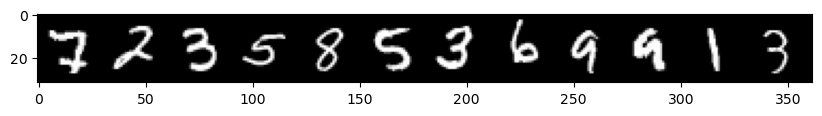

In [53]:
print("label: ", labels[:12].numpy())
im = make_grid(images[:12], nrow=12)
plt.figure(figsize=(10, 4))

plt.imshow(np.transpose(im.numpy(), (1, 2, 0)))

In [54]:
im.shape

torch.Size([3, 32, 362])

In [55]:
im[0, :, :].shape

torch.Size([32, 362])

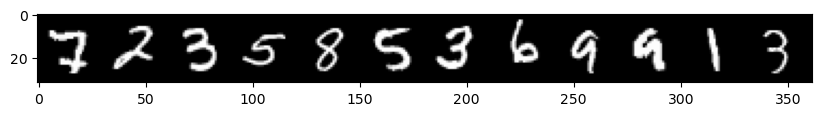

In [56]:
plt.figure(figsize=(10, 4))
plt.imshow(im[1, :, :], cmap="gray")

In [57]:
images[:10].shape

torch.Size([10, 1, 28, 28])

In [58]:
class MultilayerPerceptron(nn.Module):
    def __init__(self, in_sz=784, out_sz=10, layers=[120, 84]):
        super().__init__()
        self.fc1 = nn.Linear(in_sz, layers[0])
        self.fc2 = nn.Linear(layers[0], layers[1])
        self.fc3 = nn.Linear(layers[1], out_sz)

    def forward(self, X):
        # print(X.shape)
        X = F.relu(self.fc1(X))
        # print(X.shape)
        X = F.relu(self.fc2(X))
        # print(X.shape)
        X = self.fc3(X)
        # print(X.shape)

        # return F.log_softmax(X, dim=1)
        return X

In [59]:
model = MultilayerPerceptron()
model

MultilayerPerceptron(
  (fc1): Linear(in_features=784, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)

In [60]:
total_params = 0
for param in model.parameters():
    total_params += param.numel()
    print(param.numel(), param.shape)

print("\n", total_params)

94080 torch.Size([120, 784])
120 torch.Size([120])
10080 torch.Size([84, 120])
84 torch.Size([84])
840 torch.Size([10, 84])
10 torch.Size([10])

 105214


In [61]:
total_params = 0

for name, param in model.named_parameters():
    print(name, "\t", param.shape, f"number of params in layar {param.numel()}")
    total_params += param.numel()

print(f"\nThe total parameters in ANN: {total_params}")

fc1.weight 	 torch.Size([120, 784]) number of params in layar 94080
fc1.bias 	 torch.Size([120]) number of params in layar 120
fc2.weight 	 torch.Size([84, 120]) number of params in layar 10080
fc2.bias 	 torch.Size([84]) number of params in layar 84
fc3.weight 	 torch.Size([10, 84]) number of params in layar 840
fc3.bias 	 torch.Size([10]) number of params in layar 10

The total parameters in ANN: 105214


In [62]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [63]:
images.shape

torch.Size([100, 1, 28, 28])

In [ ]:
import time

start_time = time.time()

epochs = 10

train_losses = []
train_correct = []
test_losses = []
test_correct = []


for i in range(epochs):
    trn_corr = 0
    tst_corr = 0

    for b, (X_train, y_train) in enumerate(train_loader):
        b += 1
        y_pred = model(X_train.view(X_train.size(0), -1))

        loss = criterion(y_pred, y_train)

        predicted = torch.max(y_pred.data, 1)[1]

        # print('\ny_pred', type(y_pred), y_pred.shape, y_pred, sep='\n')
        # print('\ny_pred[0]', type(y_pred[0]), y_pred[0].shape, y_pred[0], sep='\n')

        # print('\ny_pred.data', type(y_pred.data), y_pred.data.shape, y_pred.data, sep='\n')
        # print('\ny_pred.data[0]', type(y_pred.data[0]), y_pred.data[0].shape, y_pred.data[0], sep='\n')

        batch_corr = (predicted == y_train).sum()
        trn_corr += batch_corr
        # print(batch_corr, trn_corr)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if b % 200 == 0:
            acc = trn_corr.item() * 100 / (100 * b)
            print(f"Epoch {i + 1} batch{b} loss:{loss.item():1.5f} accuracy:{acc:5.2f}")

    train_losses.append(loss.item())
    train_correct.append(trn_corr)

    with torch.no_grad():
        for b, (X_test, y_test) in enumerate(test_loader):
            y_val = model(X_test.view(X_test.size(0), -1))
            predicted = torch.max(y_val.data, 1)[1]
            tst_corr += (predicted == y_test).sum()

    loss = criterion(y_val, y_test)
    test_losses.append(loss.item())
    test_correct.append(tst_corr)

    # print(f"Batch: {b}")
    # break
    # print(y_pred.data)


# print(f"\n\n\nEpoch: {i + 1}\n\n\n")
during = time.time() - start_time
mins = during // 60
sec = during - mins * 60
print(f"Duration: {int(mins)}:{sec:2.0f}")
# break

Epoch 1 batch200 loss:0.28793 accuracy:83.05
Epoch 1 batch400 loss:0.25785 accuracy:87.43
Epoch 1 batch600 loss:0.23680 accuracy:89.46
Epoch 2 batch200 loss:0.17160 accuracy:94.78
Epoch 2 batch400 loss:0.06876 accuracy:95.09
Epoch 2 batch600 loss:0.18817 accuracy:95.34
Epoch 3 batch200 loss:0.17639 accuracy:96.50
Epoch 3 batch400 loss:0.18465 accuracy:96.52
Epoch 3 batch600 loss:0.07771 accuracy:96.67
Epoch 4 batch200 loss:0.11973 accuracy:97.54
Epoch 4 batch400 loss:0.01810 accuracy:97.56
Epoch 4 batch600 loss:0.05864 accuracy:97.52
Epoch 5 batch200 loss:0.03341 accuracy:98.14
Epoch 5 batch400 loss:0.07299 accuracy:98.07
Epoch 5 batch600 loss:0.05592 accuracy:98.05
Epoch 6 batch200 loss:0.08424 accuracy:98.50
Epoch 6 batch400 loss:0.02833 accuracy:98.52
Epoch 6 batch600 loss:0.06852 accuracy:98.40
Epoch 7 batch200 loss:0.04245 accuracy:98.78
Epoch 7 batch400 loss:0.06339 accuracy:98.72
Epoch 7 batch600 loss:0.02149 accuracy:98.70
Epoch 8 batch200 loss:0.00487 accuracy:98.99
Epoch 8 ba

In [65]:
X_train.size()

torch.Size([100, 1, 28, 28])

In [66]:
# y_pred[1].data

In [67]:
# y_pred.data[1]

In [68]:
# print(torch.max(y_pred,1)[0])
# print(torch.max(y_pred.data,1)[0])

In [69]:
# print(type(torch.max(y_pred,1)[0]))
# print(type(torch.max(y_pred.data,1)[0]))

In [70]:
# print(torch.max(y_pred,1)[1])
# print(torch.max(y_pred.data,1)[1])

In [71]:
# print(type(torch.max(y_pred,1)[1]))
# print(type(torch.max(y_pred.data,1)[1]))

In [72]:
train_losses

[0.2368019074201584,
 0.18817394971847534,
 0.07770954817533493,
 0.05864052474498749,
 0.055924028158187866,
 0.06851578503847122,
 0.02149120159447193,
 0.04878712072968483,
 0.06369747221469879,
 0.019954318180680275]

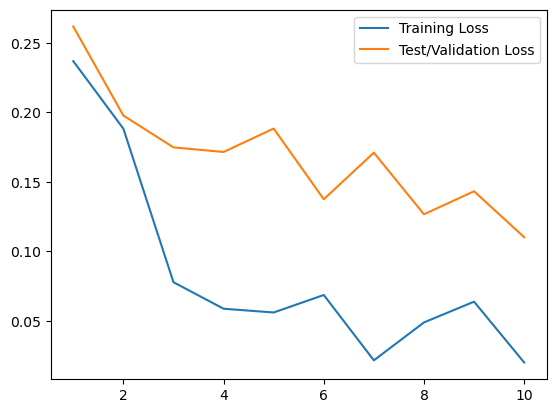

In [ ]:
plt.plot(np.arange(1, epochs + 1), train_losses, label="Training Loss")
plt.plot(np.arange(1, epochs + 1), test_losses, label="Test/Validation Loss")
plt.legend()

In [ ]:
train_accuracy = [t * 100 / len(train_data) for t in train_correct]
train_accuracy = np.array(train_correct) / 600
test_accuracy = [t * 100 / len(test_data) for t in test_correct]
# test_accuracy = np.array(test_correct)/100

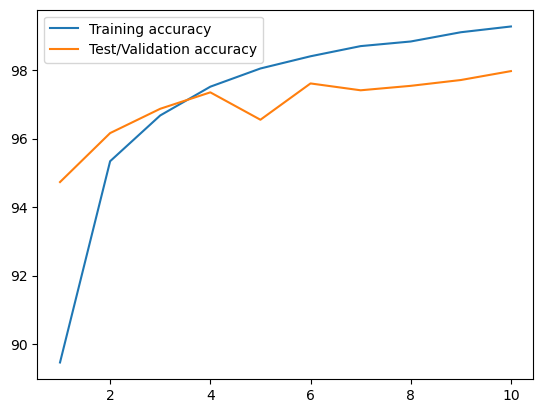

In [ ]:
plt.plot(np.arange(1, epochs + 1), train_accuracy, label="Training accuracy")
plt.plot(np.arange(1, epochs + 1), test_accuracy, label="Test/Validation accuracy")
plt.legend()

In [ ]:
test_load_all = DataLoader(test_data, batch_size=10_000, shuffle=False)

with torch.no_grad():
    correct = 0
    for X_test, y_test in test_load_all:
        y_val = model(X_test.view(X_test.shape[0], -1))
        predicted = torch.max(y_val.data, 1)[1]
        correct += (predicted == y_test).sum()
        X_incorrect = X_test[predicted != y_test, :, :, :]
        y_incorrect = y_test[predicted != y_test]

In [96]:
len(y_incorrect)

203

label:  [   6    8    1    3    3    5    8    6    2    5    2    2]


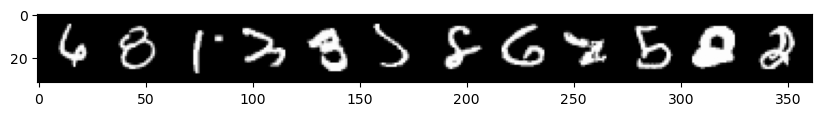

In [107]:
choose = torch.randint(len(y_incorrect), size=(1, 12)).view(-1)
print("label: ", y_incorrect[choose].numpy())
im = make_grid(X_incorrect[choose], nrow=12)
plt.figure(figsize=(10, 4))

plt.imshow(np.transpose(im.numpy(), (1, 2, 0)))


In [ ]:
confusion_matrix(predicted, y_test)

array([[ 966,    0,    2,    1,    0,    1,    0,    1,    3,    1],
       [   0, 1125,    0,    1,    1,    0,    3,    4,    0,    2],
       [   1,    4, 1009,    6,    2,    0,    5,    9,    3,    0],
       [   1,    0,    4,  987,    0,    4,    1,    2,    4,    6],
       [   1,    0,    1,    0,  962,    2,    7,    0,    3,    9],
       [   3,    0,    0,    9,    1,  874,    3,    0,    4,    4],
       [   3,    2,    2,    0,    4,    3,  937,    0,    2,    0],
       [   1,    0,    4,    3,    1,    0,    0, 1006,    2,    4],
       [   3,    4,    9,    3,    2,    6,    2,    1,  949,    1],
       [   1,    0,    1,    0,    9,    2,    0,    5,    4,  982]],
      dtype=int64)

In [ ]:
torch.save(model, "./models/ANN_CIFAR10.pt")